In [ ]:
import os
from google.colab import drive

print("Step 0: Mounting Google Drive...")

drive.mount("/content/drive")

drive_folder_path = "/content/drive/MyDrive/Applied AI/applied_ai"

if os.path.exists(drive_folder_path):
    os.chdir(drive_folder_path)
    print(f"Working directory set to: {os.getcwd()}")
else:
    print(
        f"Directory not found: {drive_folder_path}. Current directory: {os.getcwd()}"
    )

required_files = [
    "gtfs_rt_2024.csv",
    "weather_data_2024.xlsx",
    "routes.csv",
    "service_alerts_2024.parquet",
    "stops.csv",
    "transfers.csv",
    "trips.csv",
]

print("\nChecking required files in working directory:")
missing_files = []
for file in required_files:
    if os.path.exists(file):
        print(f"  [OK] {file}")
    else:
        if file == "weather_data_2024.xlsx" and os.path.exists("weather_data.xlsx"):
            print("  [OK] weather_data.xlsx (fallback)")
        else:
            print(f"  [MISSING] {file}")
            missing_files.append(file)

if len(missing_files) == 0:
    print("\nAll required files found. Ready for processing.")
else:
    print(
        f"\nWarning: {len(missing_files)} file(s) missing in the current directory."
    )

Step 0: Mounting Google Drive...
Mounted at /content/drive
Working directory set to: /content/drive/MyDrive/Applied AI/applied_ai

Checking required files in working directory:
  [OK] gtfs_rt_2024.csv
  [OK] weather_data_2024.xlsx
  [OK] routes.csv
  [OK] service_alerts_2024.parquet
  [OK] stops.csv
  [OK] transfers.csv
  [OK] trips.csv

All required files found. Ready for processing.


In [ ]:
import gc
import os
import numpy as np
import pandas as pd

print("Step 1: Reading weather data and defining categories...")

weather_file = "weather_data_2024.xlsx"
if not os.path.exists(weather_file):
    weather_file = "weather_data.xlsx"

weather_df = pd.read_excel(weather_file)
cols = list(weather_df.columns)

rain_col = next(
    (
        c
        for c in cols
        if any(
            k in c.lower()
            for k in ["regn", "rain", "precip", "nederbörd", "ned"]
        )
    ),
    None,
)
temp_col = next(
    (
        c
        for c in cols
        if any(k in c.lower() for k in ["temp", "air_temp", "temperatur"])
    ),
    None,
)
date_col = next(
    (
        c
        for c in cols
        if any(
            k in c.lower()
            for k in ["date", "time", "datum", "tid", "hour"]
        )
    ),
    cols[0],
)

weather_df["Rain"] = (
    pd.to_numeric(weather_df[rain_col], errors="coerce")
    .fillna(0)
    .astype("float32")
)
weather_df["Temp"] = (
    pd.to_numeric(weather_df[temp_col], errors="coerce")
    .fillna(10)
    .astype("float32")
)

conditions = [
    (weather_df["Rain"] == 0) & (weather_df["Temp"] <= 0),
    (weather_df["Rain"] == 0)
    & (weather_df["Temp"] > 0)
    & (weather_df["Temp"] <= 20),
    (weather_df["Rain"] == 0) & (weather_df["Temp"] > 20),
    (weather_df["Rain"] > 0)
    & (weather_df["Temp"] <= 0),
    (weather_df["Rain"] > 0)
    & (weather_df["Temp"] > 0)
    & (weather_df["Temp"] <= 20),
    (weather_df["Rain"] > 0) & (weather_df["Temp"] > 20),
]

category_names = [
    "1_Freezing_dry",
    "2_Mild_dry",
    "3_Warm_dry",
    "4_Freezing_precip",
    "5_Mild_rain",
    "6_Warm_rain",
]

weather_df["Weather_Category"] = np.select(
    conditions, category_names, default="2_Mild_dry"
)
weather_df["datetime"] = pd.to_datetime(weather_df[date_col])
weather_df["hour_key"] = weather_df["datetime"].dt.floor("h")

weather_unique = weather_df.groupby("hour_key").first().reset_index()
weather_dict = weather_unique.set_index("hour_key")[
    ["Weather_Category", "Rain", "Temp"]
].to_dict(orient="index")

print("Weather data successfully prepared.")

Step 1: Reading weather data and defining categories...
Weather data successfully prepared.


In [ ]:
print("Step 2: Processing GTFS chunks and target variable extraction...")

gtfs_file = "gtfs_rt_2024.csv"
chunk_size = 200000
max_sample_per_category = 200000

sample_chunks_by_cat = {cat: [] for cat in category_names}
stats_accumulator = {cat: {"dwell": [], "interstop": []} for cat in category_names}

chunk_count = 0
total_processed_rows = 0

for chunk in pd.read_csv(
    gtfs_file, sep=";", chunksize=chunk_size, low_memory=False
):
    chunk_count += 1
    total_processed_rows += len(chunk)

    line_col = (
        "LineNumber"
        if "LineNumber" in chunk.columns
        else ("route_id" if "route_id" in chunk.columns else None)
    )
    if not line_col:
        chunk["LineNumber"] = "1"
        line_col = "LineNumber"

    chunk = chunk[
        chunk[line_col].astype(str).isin(["1", "2", "3", "4", "5", "6"])
    ].copy()
    if len(chunk) == 0:
        continue

    if "observed_arrival_time_sfm" in chunk.columns and "date" in chunk.columns:
        chunk["date_str"] = chunk["date"].astype(str)
        chunk["datetime_base"] = pd.to_datetime(
            chunk["date_str"], format="%Y%m%d", errors="coerce"
        )
        chunk["hour_offset"] = pd.to_timedelta(
            chunk["observed_arrival_time_sfm"], unit="s", errors="coerce"
        )
        chunk["hour_key"] = (
            chunk["datetime_base"] + chunk["hour_offset"]
        ).dt.floor("h")
    else:
        date_bus_col = "date" if "date" in chunk.columns else chunk.columns[0]
        chunk["hour_key"] = pd.to_datetime(
            chunk[date_bus_col].astype(str), format="%Y%m%d", errors="coerce"
        ).dt.floor("h")

    chunk["Weather_Category"] = chunk["hour_key"].map(
        lambda x: weather_dict.get(x, {}).get(
            "Weather_Category", "2_Mild_dry"
        )
    )
    chunk["Rain"] = (
        chunk["hour_key"]
        .map(lambda x: weather_dict.get(x, {}).get("Rain", 0.0))
        .astype("float32")
    )
    chunk["Temp"] = (
        chunk["hour_key"]
        .map(lambda x: weather_dict.get(x, {}).get("Temp", 10.0))
        .astype("float32")
    )

    chunk["dwell_delay_delta"] = (
        chunk["observed_departure_delay"] - chunk["observed_arrival_delay"]
    )
    chunk = chunk.sort_values(by=["trip_id", "stop_sequence"])
    chunk["prev_departure_delay"] = chunk.groupby("trip_id")[
        "observed_departure_delay"
    ].shift(1)
    chunk["interstop_delay_delta"] = (
        chunk["observed_arrival_delay"] - chunk["prev_departure_delay"]
    )

    chunk["target_delay_in_3_stops"] = chunk.groupby("trip_id")[
        "observed_arrival_delay"
    ].shift(-3)

    clean_chunk = chunk.dropna(
        subset=[
            "dwell_delay_delta",
            "interstop_delay_delta",
            "target_delay_in_3_stops",
        ]
    ).copy()
    clean_chunk = clean_chunk[
        (clean_chunk["dwell_delay_delta"].between(-180, 300))
        & (clean_chunk["interstop_delay_delta"].between(-180, 300))
        & (clean_chunk["target_delay_in_3_stops"].between(-300, 1800))
    ]

    for cat in category_names:
        cat_data = clean_chunk[clean_chunk["Weather_Category"] == cat]
        if len(cat_data) > 0:
            stats_accumulator[cat]["dwell"].extend(
                cat_data["dwell_delay_delta"].tolist()
            )
            stats_accumulator[cat]["interstop"].extend(
                cat_data["interstop_delay_delta"].tolist()
            )

            current_samples = sum([len(c) for c in sample_chunks_by_cat[cat]])
            if current_samples < max_sample_per_category:
                sample_cols = [
                    "stop_sequence",
                    line_col,
                    "Rain",
                    "Temp",
                    "observed_arrival_delay",
                    "target_delay_in_3_stops",
                ]
                sample_chunk = cat_data[sample_cols].copy()
                if line_col != "LineNumber":
                    sample_chunk.rename(
                        columns={line_col: "LineNumber"}, inplace=True
                    )
                sample_chunks_by_cat[cat].append(sample_chunk)

    print(
        f"  -> Chunk {chunk_count} processed ({total_processed_rows:,} rows)...",
        end="\r",
    )

    del chunk, clean_chunk
    gc.collect()

print(f"\nProcessing complete: {total_processed_rows:,} total rows.")

Step 2: Processing GTFS chunks and target variable extraction...

Processing complete: 9,477,214 total rows.


In [ ]:
print("Step 3: Calculating statistical summary for weather categories...")

stats_summary = []
for cat in category_names:
    dwell_vals = stats_accumulator[cat]["dwell"]
    inter_vals = stats_accumulator[cat]["interstop"]

    if len(dwell_vals) > 0:
        stats_summary.append(
            {
                "Weather_Category": cat,
                "Avg_Dwell_Delay_sec": round(np.mean(dwell_vals), 2),
                "Median_Dwell_Delay_sec": round(np.median(dwell_vals), 2),
                "Avg_Interstop_Delay_sec": round(np.mean(inter_vals), 2),
                "Median_Interstop_Delay_sec": round(np.median(inter_vals), 2),
                "Sample_Count": len(dwell_vals),
            }
        )

summary_df = pd.DataFrame(stats_summary)

print("\n--------------------------------------------------------")
print("--- MEAN AND MEDIAN DELAY DELTAS BY WEATHER (sec) ---")
print("--------------------------------------------------------")
print(summary_df.to_string(index=False))

del stats_accumulator
gc.collect()

Step 3: Calculating statistical summary for weather categories...

--------------------------------------------------------
--- MEAN AND MEDIAN DELAY DELTAS BY WEATHER (sec) ---
--------------------------------------------------------
 Weather_Category  Avg_Dwell_Delay_sec  Median_Dwell_Delay_sec  Avg_Interstop_Delay_sec  Median_Interstop_Delay_sec  Sample_Count
   1_Freezing_dry                21.67                    17.0                     3.71                        -8.0        618247
       2_Mild_dry                22.68                    17.0                    -0.43                       -11.0       3260991
       3_Warm_dry                24.83                    19.0                     1.61                       -12.0        501345
4_Freezing_precip                24.82                    20.0                    26.90                        20.0          2624
      5_Mild_rain                23.60                    18.0                     3.29                       -10.0

0

In [ ]:
import gc
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("Step 4: Preparing datasets for model comparison...")

prepared_datasets = {}

for cat in category_names:
    if (
        cat not in sample_chunks_by_cat
        or len(sample_chunks_by_cat[cat]) == 0
    ):
        print(f"Warning: Insufficient data for category {cat}")
        continue

    cat_df = pd.concat(sample_chunks_by_cat[cat], ignore_index=True)

    X_cat = cat_df[
        ["stop_sequence", "LineNumber", "Rain", "Temp", "observed_arrival_delay"]
    ].copy()
    y_cat = cat_df["target_delay_in_3_stops"].copy()

    X_cat["LineNumber"] = X_cat["LineNumber"].astype(str)

    X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
        X_cat, y_cat, test_size=0.2, random_state=42
    )

    num_cols = ["stop_sequence", "Rain", "Temp", "observed_arrival_delay"]
    cat_cols = ["LineNumber"]

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ]
    )

    X_train_proc = preprocessor.fit_transform(X_train_c)
    X_test_proc = preprocessor.transform(X_test_c)

    prepared_datasets[cat] = {
        "X_train": X_train_proc,
        "X_test": X_test_proc,
        "y_train": y_train_c,
        "y_test": y_test_c,
        "preprocessor": preprocessor,
        "rows_count": len(cat_df),
    }

    print(f"  - {cat}: {len(cat_df):,} rows processed.")

del sample_chunks_by_cat
gc.collect()

print("Dataset preparation complete.")

Step 4: Preparing datasets for model comparison...
  - 1_Freezing_dry: 217,313 rows processed.
  - 2_Mild_dry: 246,191 rows processed.
  - 3_Warm_dry: 240,136 rows processed.
  - 4_Freezing_precip: 2,624 rows processed.
  - 5_Mild_rain: 200,344 rows processed.
  - 6_Warm_rain: 1,468 rows processed.
Dataset preparation complete.


In [ ]:
import joblib
import tensorflow as tf
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow import keras
from tensorflow.keras import layers

print("Step 5: Training and evaluating models...")

best_models = {}
comparison_results = []

for cat in category_names:
    if cat not in prepared_datasets:
        continue

    print(f"\n----------------------------------------------------------------------")
    print(f"Evaluating Models for Weather Category: '{cat}' ({prepared_datasets[cat]['rows_count']:,} samples)")
    print(f"----------------------------------------------------------------------")

    data = prepared_datasets[cat]
    X_train, X_test = data["X_train"], data["X_test"]
    y_train, y_test = data["y_train"], data["y_test"]

    # --- 1. Linear Regression ---
    print("  1/5 Training Linear Regression...")
    lr = LinearRegression()
    lr.fit(X_train, y_train)
    pred_lr = lr.predict(X_test)
    mae_lr = mean_absolute_error(y_test, pred_lr)

    # --- 2. Ridge Regression ---
    print("  2/5 Training Ridge Regression...")
    ridge = Ridge(alpha=1.0)
    ridge.fit(X_train, y_train)
    pred_ridge = ridge.predict(X_test)
    mae_ridge = mean_absolute_error(y_test, pred_ridge)

    # --- 3. Random Forest Regressor ---
    print("  3/5 Training Random Forest (n_estimators=50)...")
    rf = RandomForestRegressor(
        n_estimators=50, max_depth=12, random_state=42, n_jobs=-1
    )
    rf.fit(X_train, y_train)
    pred_rf = rf.predict(X_test)
    mae_rf = mean_absolute_error(y_test, pred_rf)

    # --- 4. Gradient Boosting Regressor ---
    print("  4/5 Training Gradient Boosting...")
    gbr = GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42
    )
    gbr.fit(X_train, y_train)
    pred_gbr = gbr.predict(X_test)
    mae_gbr = mean_absolute_error(y_test, pred_gbr)

    # --- 5. Deep Neural Network (Keras) ---
    print("  5/5 Training Deep Neural Network (Keras)...")
    nn_model = keras.Sequential(
        [
            layers.Input(shape=(X_train.shape[1],)),
            layers.Dense(64, activation="relu"),
            layers.BatchNormalization(),
            layers.Dropout(0.2),
            layers.Dense(32, activation="relu"),
            layers.Dense(1),
        ]
    )
    nn_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )

    history = nn_model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=12,
        batch_size=256,
        callbacks=[early_stop],
        verbose=0,
    )
    pred_nn = nn_model.predict(X_test, verbose=0).flatten()
    mae_nn = mean_absolute_error(y_test, pred_nn)

    models_dict = {
        "Linear Regression": (lr, mae_lr, pred_lr, None),
        "Ridge Regression": (ridge, mae_ridge, pred_ridge, None),
        "Random Forest": (rf, mae_rf, pred_rf, None),
        "Gradient Boosting": (gbr, mae_gbr, pred_gbr, None),
        "Neural Network": (nn_model, mae_nn, pred_nn, history),
    }

    for m_name, (_, m_mae, _, _) in models_dict.items():
        comparison_results.append(
            {
                "Weather_Category": cat,
                "Model": m_name,
                "MAE_sec": round(m_mae, 2),
            }
        )

    best_model_name = min(models_dict, key=lambda k: models_dict[k][1])
    best_model_obj, best_mae, best_pred, best_hist = models_dict[
        best_model_name
    ]

    print(
        f"  ---> Best Model for {cat}: {best_model_name} (MAE: {best_mae:.2f} seconds)"
    )

    filename_base = f"best_model_3_stops_{cat}"
    if best_model_name == "Neural Network":
        best_model_obj.save(f"{filename_base}.keras")
    else:
        joblib.dump(best_model_obj, f"{filename_base}.pkl")

    best_models[cat] = {
        "name": best_model_name,
        "model": best_model_obj,
        "mae": best_mae,
        "predictions": best_pred,
        "history": best_hist,
        "all_models": models_dict,
    }

print("\nModel training and selection completed for all categories.")

Step 5: Training and evaluating models...

----------------------------------------------------------------------
Evaluating Models for Weather Category: '1_Freezing_dry' (217,313 samples)
----------------------------------------------------------------------
  1/5 Training Linear Regression...
  2/5 Training Ridge Regression...
  3/5 Training Random Forest (n_estimators=50)...
  4/5 Training Gradient Boosting...
  5/5 Training Deep Neural Network (Keras)...
  ---> Best Model for 1_Freezing_dry: Gradient Boosting (MAE: 84.23 seconds)

----------------------------------------------------------------------
Evaluating Models for Weather Category: '2_Mild_dry' (246,191 samples)
----------------------------------------------------------------------
  1/5 Training Linear Regression...
  2/5 Training Ridge Regression...
  3/5 Training Random Forest (n_estimators=50)...
  4/5 Training Gradient Boosting...
  5/5 Training Deep Neural Network (Keras)...
  ---> Best Model for 2_Mild_dry: Gradient 

In [ ]:
import gc
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

print("Step 6: Running multi-stop horizon experiments (1-10 stops)...")

horizons = list(range(1, 11))
category_horizon_results = {}

if "sample_chunks_by_cat" not in globals():
    raise NameError("Error: 'sample_chunks_by_cat' is missing. Run Step 2 first.")

for cat in category_names:
    if (
        cat not in sample_chunks_by_cat
        or len(sample_chunks_by_cat[cat]) == 0
    ):
        continue

    cat_df = pd.concat(sample_chunks_by_cat[cat], ignore_index=True)

    if len(cat_df) < 500:
        continue

    print(f"\n----------------------------------------------------------------------")
    print(f"Horizon Analysis: '{cat}' ({len(cat_df):,} samples)")
    print(f"----------------------------------------------------------------------")

    if "trip_id" in cat_df.columns and "stop_sequence" in cat_df.columns:
        cat_df = cat_df.sort_values(by=["trip_id", "stop_sequence"])
        for h in horizons:
            cat_df[f"target_delay_{h}"] = cat_df.groupby("trip_id")[
                "observed_arrival_delay"
            ].shift(-h)
    else:
        for h in horizons:
            cat_df[f"target_delay_{h}"] = cat_df[
                "observed_arrival_delay"
            ].shift(-h)

    horizon_cols = [f"target_delay_{h}" for h in horizons]
    valid_df = cat_df.dropna(subset=horizon_cols).copy()

    if len(valid_df) < 300:
        print(f"Warning: Insufficient rows for 10-stop shift in {cat}.")
        continue

    feature_cols = []
    if "stop_sequence" in valid_df.columns:
        feature_cols.append("stop_sequence")
    feature_cols.append("observed_arrival_delay")

    X_base = valid_df[feature_cols + ["LineNumber"]].copy()
    X_base["LineNumber"] = X_base["LineNumber"].astype(str)

    num_cols = feature_cols
    cat_cols = ["LineNumber"]

    num_pipeline = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )
    cat_pipeline = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "encoder",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            ),
        ]
    )

    preprocessor = ColumnTransformer(
        [
            ("num", num_pipeline, num_cols),
            ("cat", cat_pipeline, cat_cols),
        ]
    )
    X_proc = preprocessor.fit_transform(X_base)

    mae_by_horizon = []
    best_model_names = []

    for h in horizons:
        y_h = valid_df[f"target_delay_{h}"]
        X_tr, X_te, y_tr, y_te = train_test_split(
            X_proc, y_h, test_size=0.2, random_state=42
        )

        # --- 1. Linear Regression ---
        lr = LinearRegression().fit(X_tr, y_tr)
        mae_lr = mean_absolute_error(y_te, lr.predict(X_te))

        # --- 2. Ridge Regression ---
        ridge = Ridge(alpha=1.0).fit(X_tr, y_tr)
        mae_ridge = mean_absolute_error(y_te, ridge.predict(X_te))

        # --- 3. Random Forest Regressor ---
        rf = RandomForestRegressor(
            n_estimators=30, max_depth=10, random_state=42, n_jobs=-1
        ).fit(X_tr, y_tr)
        mae_rf = mean_absolute_error(y_te, rf.predict(X_te))

        # --- 4. Gradient Boosting Regressor ---
        gbr = GradientBoostingRegressor(
            n_estimators=50, max_depth=5, random_state=42
        ).fit(X_tr, y_tr)
        mae_gbr = mean_absolute_error(y_te, gbr.predict(X_te))

        # --- 5. Deep Neural Network (Keras) ---
        nn_model = keras.Sequential(
            [
                layers.Input(shape=(X_tr.shape[1],)),
                layers.Dense(64, activation="relu"),
                layers.BatchNormalization(),
                layers.Dropout(0.2),
                layers.Dense(32, activation="relu"),
                layers.Dense(1),
            ]
        )
        nn_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True
        )
        nn_model.fit(
            X_tr,
            y_tr,
            validation_split=0.2,
            epochs=10,
            batch_size=256,
            callbacks=[early_stop],
            verbose=0,
        )
        pred_nn = nn_model.predict(X_te, verbose=0).flatten()
        mae_nn = mean_absolute_error(y_te, pred_nn)

        models_eval = {
            "Linear Regression": mae_lr,
            "Ridge Regression": mae_ridge,
            "Random Forest": mae_rf,
            "Gradient Boosting": mae_gbr,
            "Neural Network": mae_nn,
        }

        best_h_name = min(models_eval, key=models_eval.get)
        best_h_mae = models_eval[best_h_name]

        mae_by_horizon.append(best_h_mae)
        best_model_names.append(best_h_name)
        print(
            f"  Horizon +{h} stops -> Best: {best_h_name:<18} | MAE: {best_h_mae:.2f} s"
        )

    mae_diffs = np.diff(mae_by_horizon)
    max_diff_idx = int(np.argmax(mae_diffs) + 1)

    category_horizon_results[cat] = {
        "horizons": horizons,
        "mae": mae_by_horizon,
        "models": best_model_names,
        "break_point": max_diff_idx,
        "sample_count": len(valid_df),
    }

print("\nMulti-stop horizon analysis finished successfully.")

Step 6: Running multi-stop horizon experiments (1-10 stops)...

----------------------------------------------------------------------
Horizon Analysis: '1_Freezing_dry' (217,313 samples)
----------------------------------------------------------------------
  Horizon +1 stops -> Best: Random Forest      | MAE: 78.23 s
  Horizon +2 stops -> Best: Random Forest      | MAE: 75.19 s
  Horizon +3 stops -> Best: Random Forest      | MAE: 73.09 s
  Horizon +4 stops -> Best: Random Forest      | MAE: 72.50 s
  Horizon +5 stops -> Best: Random Forest      | MAE: 87.56 s
  Horizon +6 stops -> Best: Random Forest      | MAE: 80.38 s
  Horizon +7 stops -> Best: Random Forest      | MAE: 92.85 s
  Horizon +8 stops -> Best: Random Forest      | MAE: 87.43 s
  Horizon +9 stops -> Best: Random Forest      | MAE: 91.42 s
  Horizon +10 stops -> Best: Random Forest      | MAE: 95.89 s

----------------------------------------------------------------------
Horizon Analysis: '2_Mild_dry' (246,191 samples)

Generating output visualization...


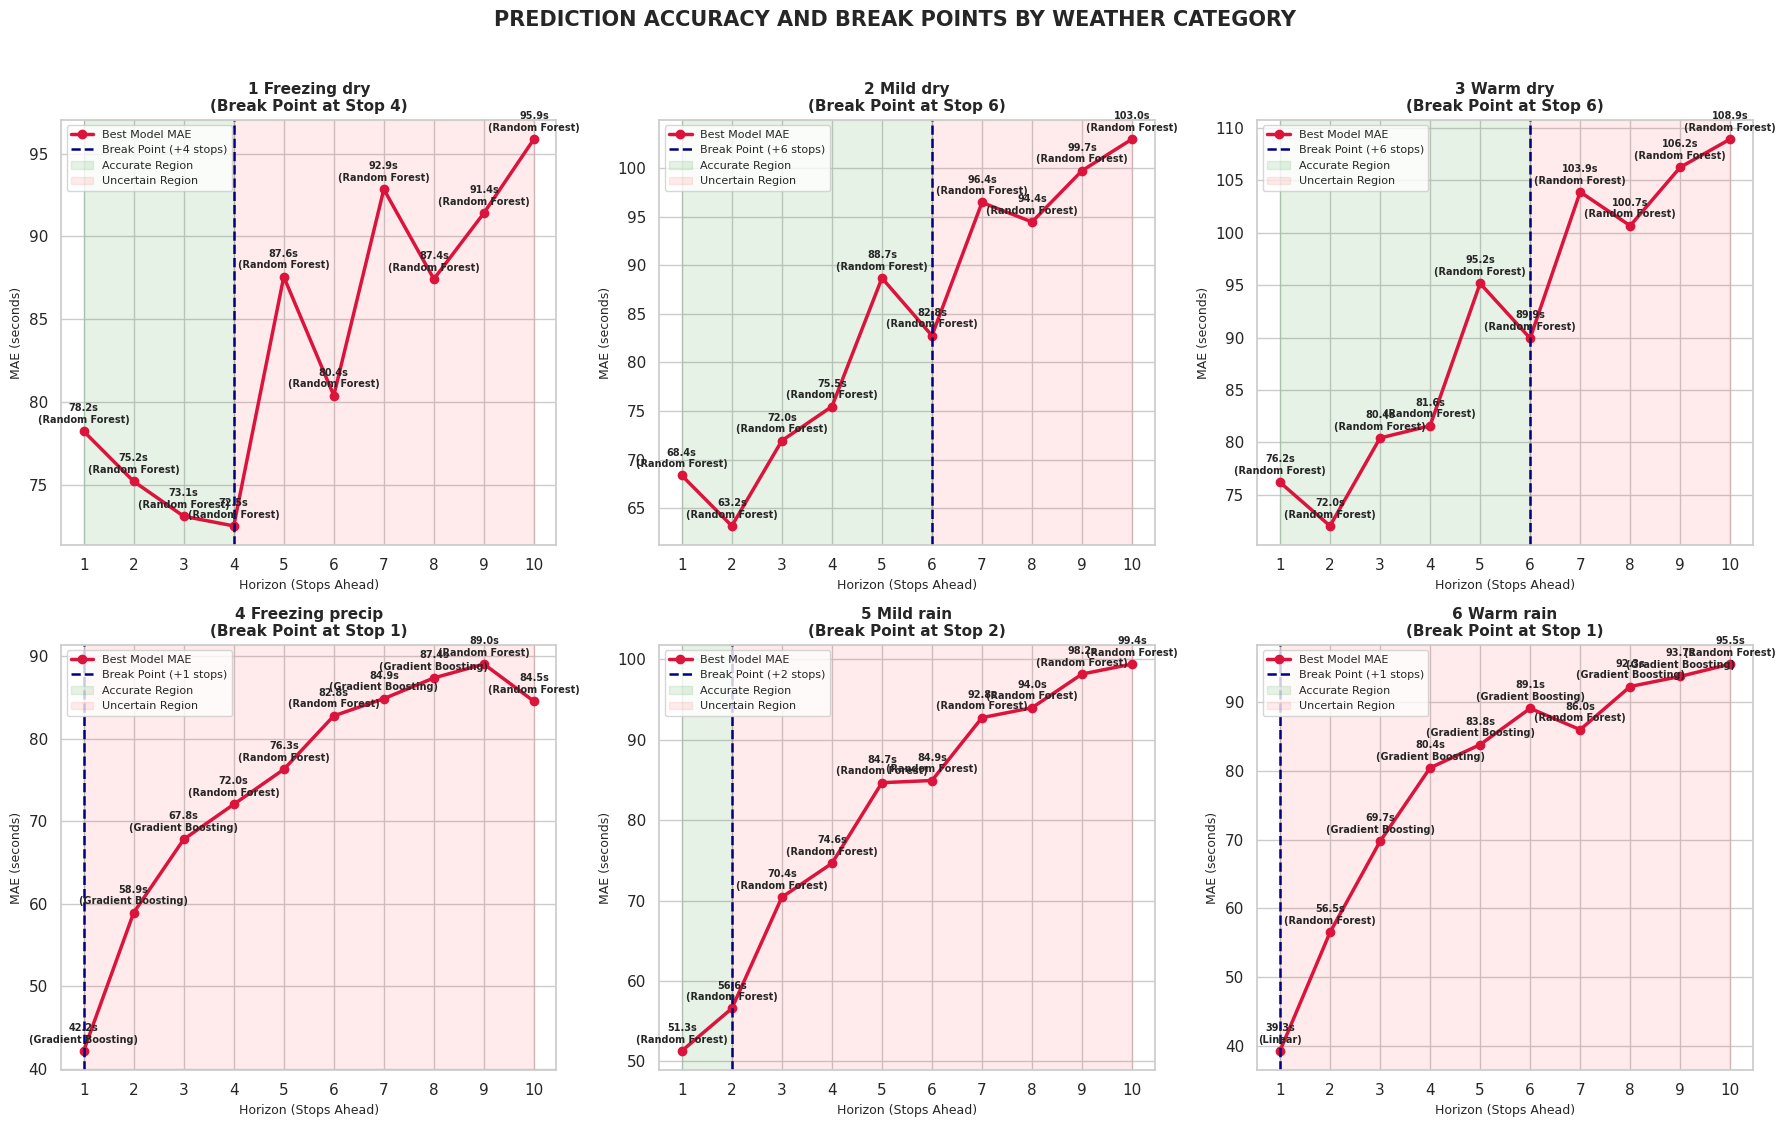


Plot saved successfully as '6_all_weather_5models_horizons.png'


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})

print("Generating output visualization...")

num_cats = len(category_horizon_results)
if num_cats == 0:
    print("Warning: No category results to plot.")
else:
    cols = 3
    rows = (num_cats + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(18, 5.5 * rows))
    if num_cats == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for idx, (cat, res) in enumerate(category_horizon_results.items()):
        ax = axes[idx]
        clean_cat_title = cat.replace("_", " ")

        horiz = res["horizons"]
        mae_list = res["mae"]
        bp = res["break_point"]
        winners = res["models"]

        ax.plot(
            horiz,
            mae_list,
            marker="o",
            linewidth=2.5,
            color="crimson",
            label="Best Model MAE",
        )

        ax.axvline(
            x=bp,
            color="navy",
            linestyle="--",
            linewidth=1.8,
            label=f"Break Point (+{bp} stops)",
        )
        ax.axvspan(1, bp, color="green", alpha=0.1, label="Accurate Region")
        ax.axvspan(bp, 10, color="red", alpha=0.08, label="Uncertain Region")

        ax.set_title(
            f"{clean_cat_title}\n(Break Point at Stop {bp})",
            fontsize=11,
            fontweight="bold",
        )
        ax.set_xlabel("Horizon (Stops Ahead)", fontsize=9)
        ax.set_ylabel("MAE (seconds)", fontsize=9)
        ax.set_xticks(horiz)
        ax.legend(loc="upper left", fontsize=8)

        for h_val, mae_val, w_name in zip(horiz, mae_list, winners):
            short_name = w_name.replace(" Regression", "").replace(" Network", "")
            ax.annotate(
                f"{mae_val:.1f}s\n({short_name})",
                (h_val, mae_val),
                textcoords="offset points",
                xytext=(0, 6),
                ha="center",
                fontsize=7,
                fontweight="bold",
            )

    for j in range(num_cats, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(
        "PREDICTION ACCURACY AND BREAK POINTS BY WEATHER CATEGORY",
        fontsize=15,
        fontweight="bold",
        y=1.02,
    )
    plt.tight_layout()
    plt.savefig("6_all_weather_5models_horizons.png", dpi=300, bbox_inches="tight")
    plt.show()

    print("\nPlot saved successfully as '6_all_weather_5models_horizons.png'")

--> Generating visualization plots...


/tmp/ipykernel_3072/644210146.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_3072/644210146.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


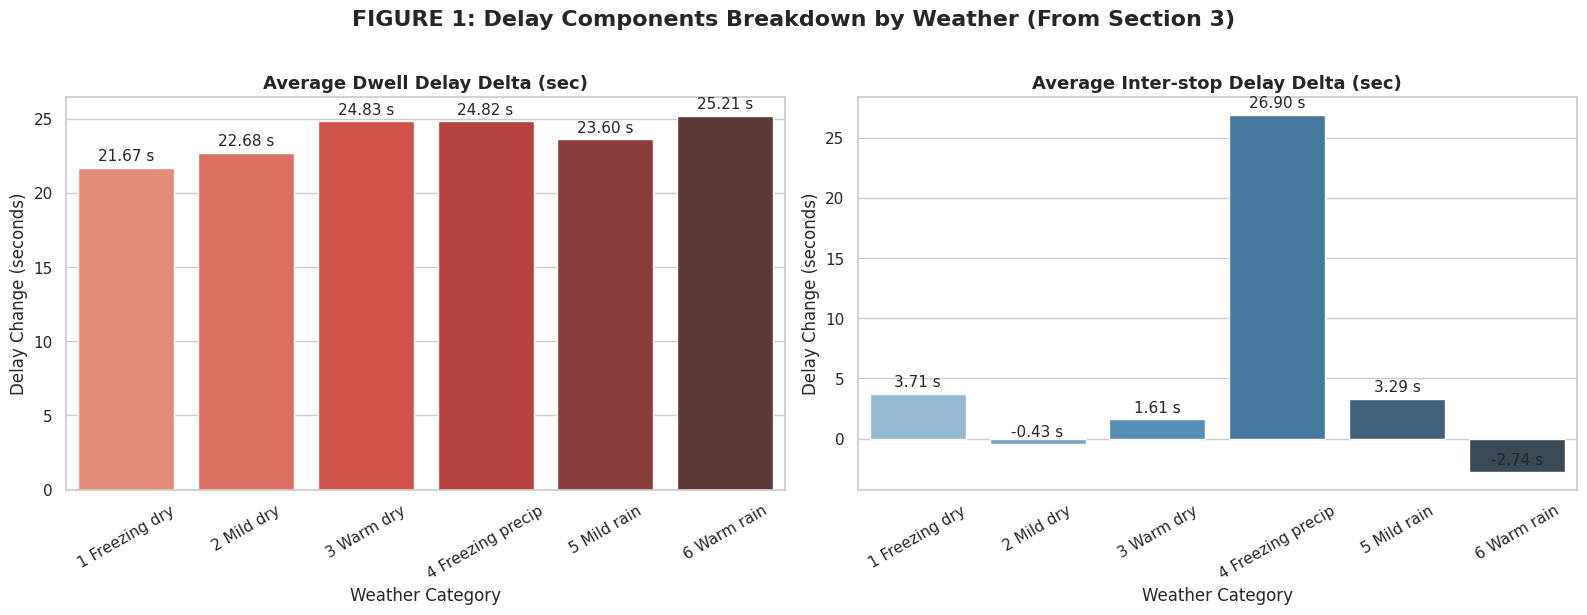

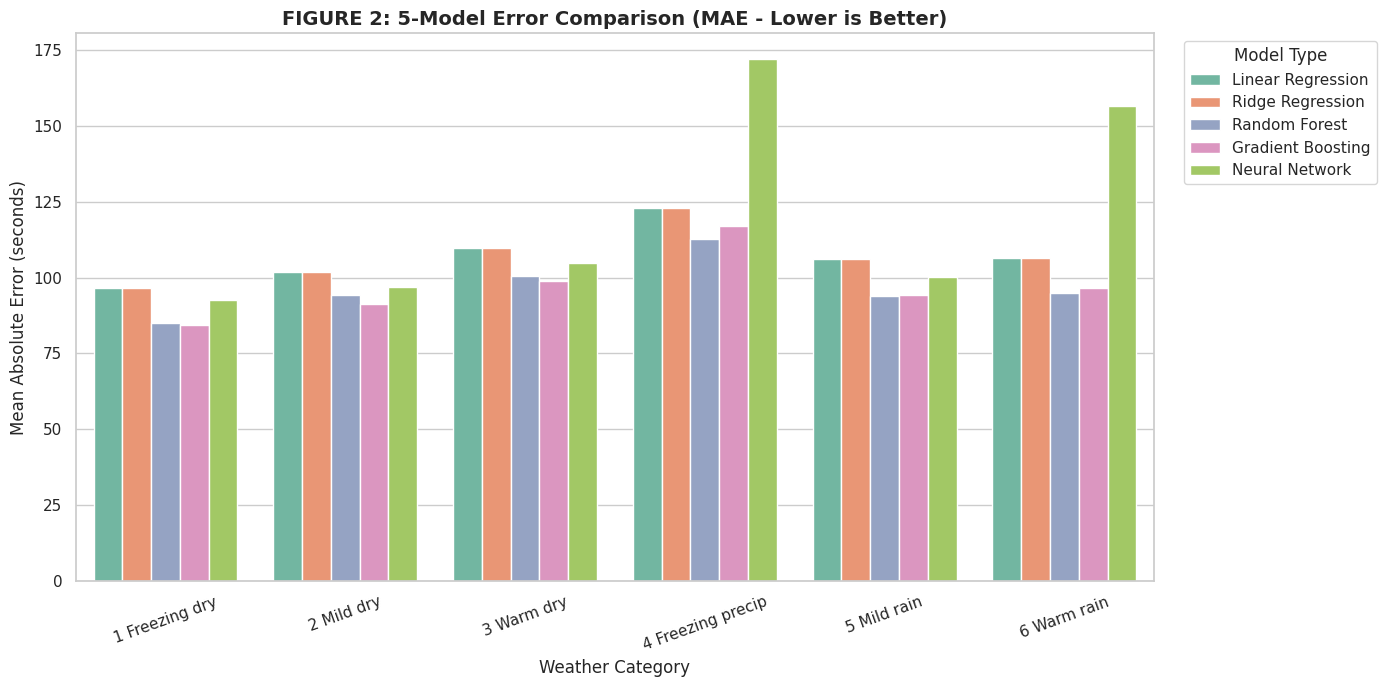

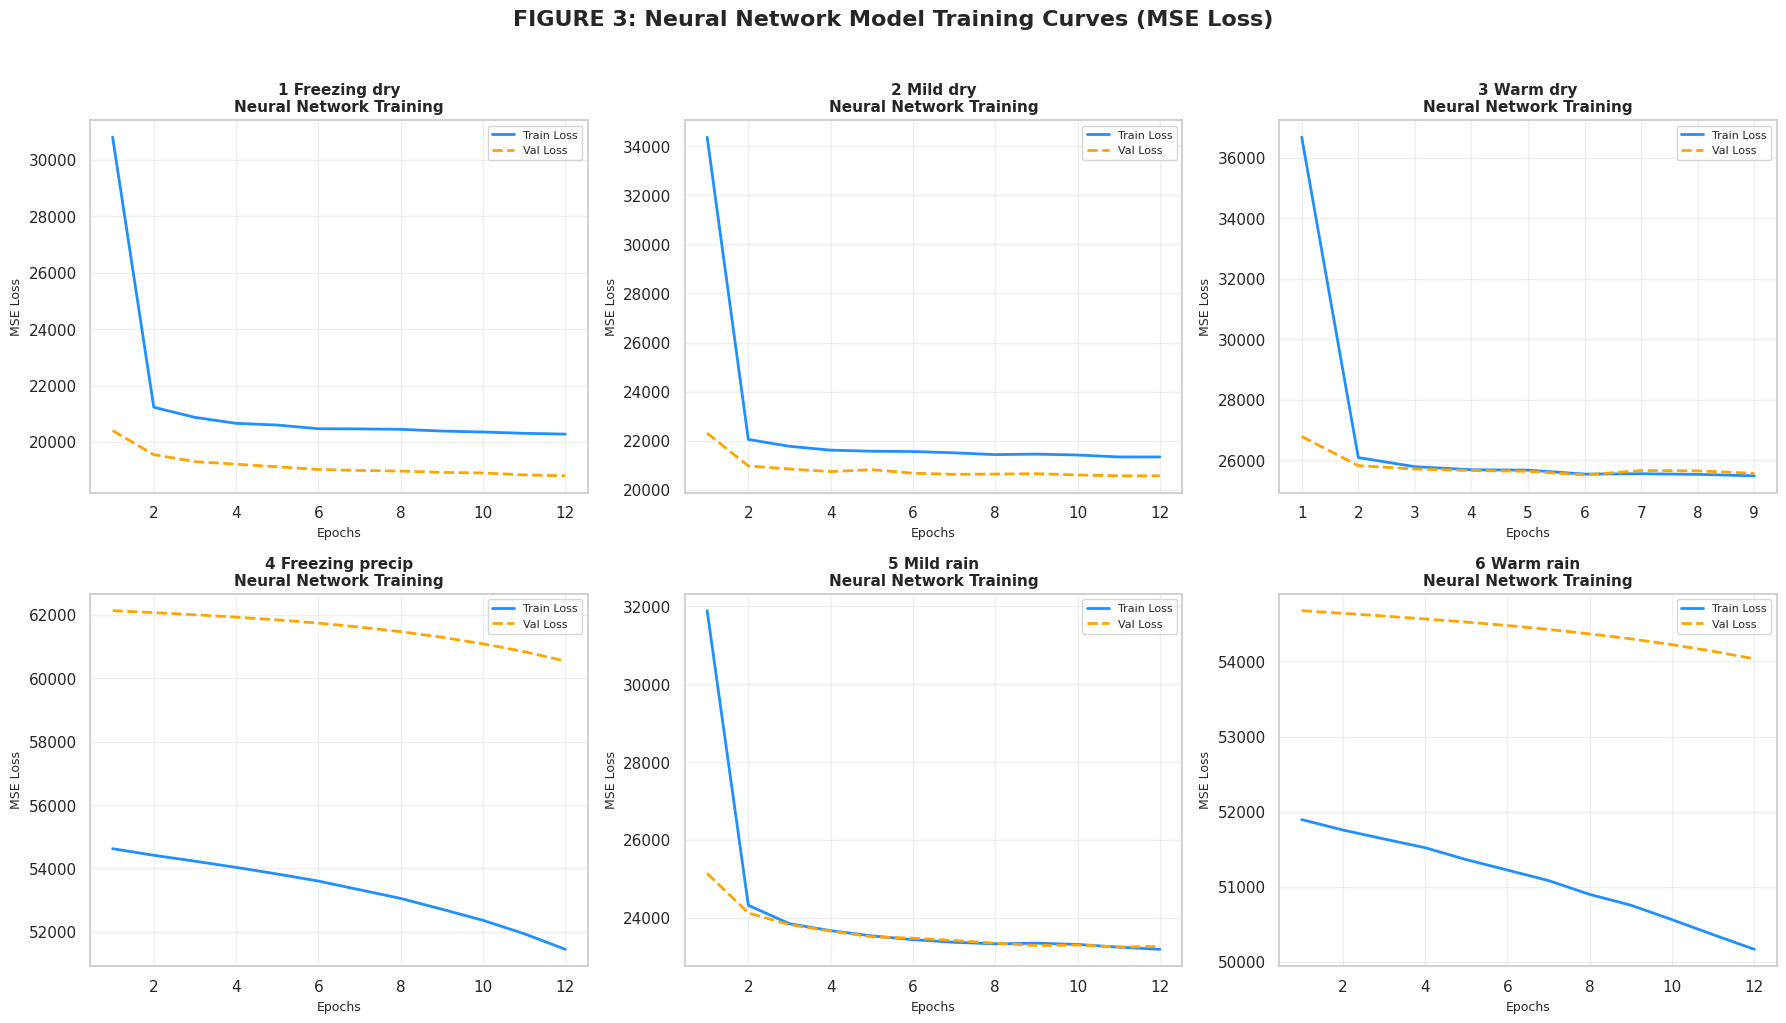

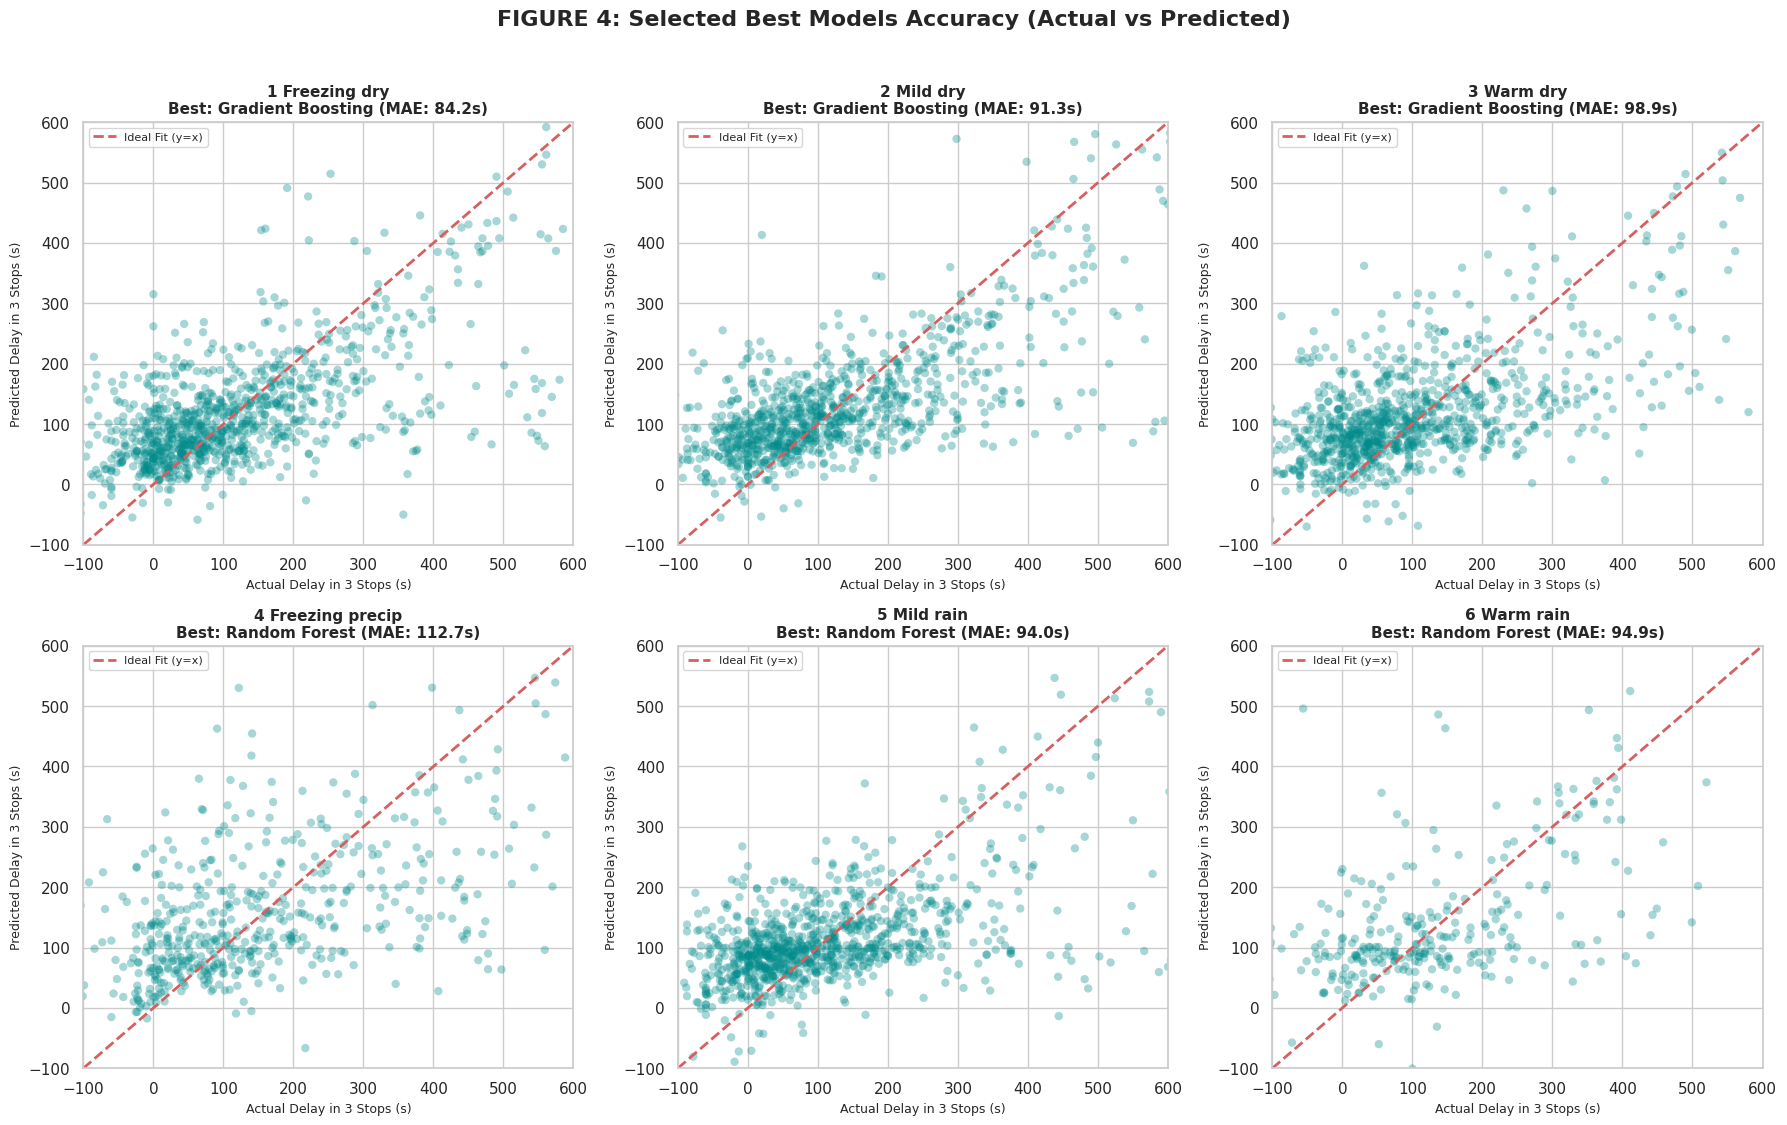


All plots generated and saved successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

print("--> Generating visualization plots...")

# ==============================================================================
# FIGURE 1: SECTION 3 STATISTICS (Dwell vs Inter-stop Delay Breakdown)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_df = summary_df.copy()
plot_df["Category"] = plot_df["Weather_Category"].str.replace("_", " ")

sns.barplot(
    data=plot_df,
    x="Category",
    y="Avg_Dwell_Delay_sec",
    ax=axes[0],
    palette="Reds_d",
)
axes[0].set_title(
    "Average Dwell Delay Delta (sec)", fontsize=13, fontweight="bold"
)
axes[0].set_xlabel("Weather Category")
axes[0].set_ylabel("Delay Change (seconds)")
axes[0].tick_params(axis="x", rotation=30)

for p in axes[0].patches:
    axes[0].annotate(
        f"{p.get_height():.2f} s",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points",
    )

sns.barplot(
    data=plot_df,
    x="Category",
    y="Avg_Interstop_Delay_sec",
    ax=axes[1],
    palette="Blues_d",
)
axes[1].set_title(
    "Average Inter-stop Delay Delta (sec)", fontsize=13, fontweight="bold"
)
axes[1].set_xlabel("Weather Category")
axes[1].set_ylabel("Delay Change (seconds)")
axes[1].tick_params(axis="x", rotation=30)

for p in axes[1].patches:
    axes[1].annotate(
        f"{p.get_height():.2f} s",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points",
    )

plt.suptitle(
    "FIGURE 1: Delay Components Breakdown by Weather (From Section 3)",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)
plt.savefig("1_delay_components_impact.png", dpi=300, bbox_inches="tight")
plt.show()


# ==============================================================================
# FIGURE 2: 5-MODEL COMPARISON BY CATEGORY (MAE)
# ==============================================================================
comp_df = pd.DataFrame(comparison_results)
comp_df["Category"] = comp_df["Weather_Category"].str.replace("_", " ")

plt.figure(figsize=(14, 7))
ax = sns.barplot(
    data=comp_df,
    x="Category",
    y="MAE_sec",
    hue="Model",
    palette="Set2",
)
plt.title(
    "FIGURE 2: 5-Model Error Comparison (MAE - Lower is Better)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Weather Category")
plt.ylabel("Mean Absolute Error (seconds)")
plt.xticks(rotation=20)
plt.legend(title="Model Type", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.savefig("2_model_comparison_by_weather.png", dpi=300, bbox_inches="tight")
plt.show()


# ==============================================================================
# FIGURE 3: NEURAL NETWORK LEARNING CURVES (Loss Curves)
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, cat in enumerate(category_names):
    ax = axes[idx]
    clean_title = cat.replace("_", " ")

    if cat in best_models:
        nn_hist = best_models[cat]["all_models"]["Neural Network"][3]
        if nn_hist is not None:
            h = nn_hist.history
            epochs = range(1, len(h["loss"]) + 1)
            ax.plot(
                epochs,
                h["loss"],
                label="Train Loss",
                color="dodgerblue",
                linewidth=2,
            )
            ax.plot(
                epochs,
                h["val_loss"],
                label="Val Loss",
                color="orange",
                linestyle="--",
                linewidth=2,
            )
            ax.set_title(
                f"{clean_title}\nNeural Network Training",
                fontsize=11,
                fontweight="bold",
            )
            ax.set_xlabel("Epochs", fontsize=9)
            ax.set_ylabel("MSE Loss", fontsize=9)
            ax.legend(fontsize=8)
            ax.grid(True, alpha=0.3)

plt.suptitle(
    "FIGURE 3: Neural Network Model Training Curves (MSE Loss)",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig("3_nn_learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()


# ==============================================================================
# FIGURE 4: BEST MODEL ACCURACY (Actual vs Predicted)
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for idx, cat in enumerate(category_names):
    if cat not in best_models or cat not in prepared_datasets:
        continue

    bm_info = best_models[cat]
    data = prepared_datasets[cat]

    y_test_sample = data["y_test"].iloc[:1000]
    y_pred_sample = bm_info["predictions"][:1000]

    ax = axes[idx]
    ax.scatter(
        y_test_sample,
        y_pred_sample,
        alpha=0.35,
        color="darkcyan",
        edgecolors="none",
    )
    ax.plot(
        [-100, 600],
        [-100, 600],
        "r--",
        linewidth=2,
        label="Ideal Fit (y=x)",
    )

    clean_title = cat.replace("_", " ")
    ax.set_title(
        f"{clean_title}\nBest: {bm_info['name']} (MAE: {bm_info['mae']:.1f}s)",
        fontsize=11,
        fontweight="bold",
    )
    ax.set_xlabel("Actual Delay in 3 Stops (s)", fontsize=9)
    ax.set_ylabel("Predicted Delay in 3 Stops (s)", fontsize=9)
    ax.set_xlim([-100, 600])
    ax.set_ylim([-100, 600])
    ax.legend(loc="upper left", fontsize=8)

plt.suptitle(
    "FIGURE 4: Selected Best Models Accuracy (Actual vs Predicted)",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig("4_best_models_accuracy_grid.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nAll plots generated and saved successfully.")